# ESTACIONARIEDAD DE SERIES TEMPORALES

Analizad la estacionariedad de la siguiente serie temporal.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

<Axes: title={'center': 'Annual Livestock'}, xlabel='date'>

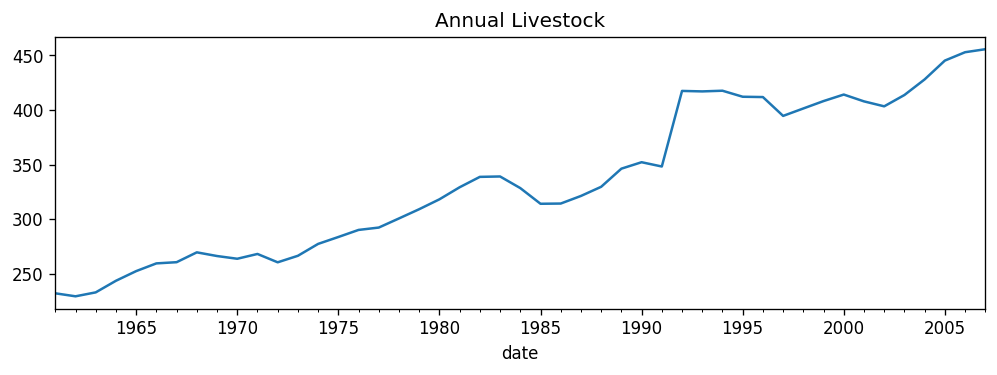

In [4]:
path = 'https://raw.githubusercontent.com/selva86/datasets/master/livestock.csv'
df = pd.read_csv(path, parse_dates=['date'], index_col='date')
fig, axes = plt.subplots(1,1, dpi=120)
df.plot(title='Annual Livestock', figsize=(10,3), legend=None, ax=axes)

Nos encontramos con una serie temporal que presenta tendencia, por lo que no es estacionaria, ya que la media no es constante en el tiempo. 

In [6]:
# ADF test

from statsmodels.tsa.stattools import adfuller
def adf_test(series):
    result = adfuller(series, autolag='AIC')
    print(f'ADF Statistic: {result[0]}')
    print(f'p-value: {result[1]}')
    for key, value in result[4].items():
        print('Critial Values:')
        print(f'   {key}, {value}')

adf_test(df)

ADF Statistic: -0.23838372529910107
p-value: 0.9337890318823665
Critial Values:
   1%, -3.5812576580093696
Critial Values:
   5%, -2.9267849124681518
Critial Values:
   10%, -2.6015409829867675


El p-valor NO es menor que el nivel de significación por lo que es una serie temporal NO ESTACIONARIA.

In [7]:
# KPSS test
from statsmodels.tsa.stattools import kpss
def kpss_test(series, **kw):    
    statistic, p_value, n_lags, critical_values = kpss(series, **kw)
    # Format Output
    print(f'KPSS Statistic: {statistic}')
    print(f'p-value: {p_value}')
    print(f'num lags: {n_lags}')
    print('Critial Values:')
    for key, value in critical_values.items():
        print(f'   {key} : {value}')
    print(f'Result: The series is {"not " if p_value < 0.05 else ""}stationary')

kpss_test(df)

KPSS Statistic: 1.026377056837458
p-value: 0.01
num lags: 4
Critial Values:
   10% : 0.347
   5% : 0.463
   2.5% : 0.574
   1% : 0.739
Result: The series is not stationary


c:\Users\icalvo\Anaconda3\envs\ds3\Lib\site-packages\statsmodels\tsa\stattools.py:2018: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  warnings.warn(


Ahora vamos a especificar que la serie tiene tendencia y volvemos a lanzar el test KPSS.

In [8]:
kpss_test(df, regression='ct')

KPSS Statistic: 0.06679313949828991
p-value: 0.1
num lags: 3
Critial Values:
   10% : 0.119
   5% : 0.146
   2.5% : 0.176
   1% : 0.216
Result: The series is stationary


c:\Users\icalvo\Anaconda3\envs\ds3\Lib\site-packages\statsmodels\tsa\stattools.py:2022: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  warnings.warn(


Por lo tanto, si elimino la tendencia de la serie, tendré como resultado una serie estacionaria. Vamos a probarlo eliminando la tendencia de la serie mediante diferenciación.

<Axes: xlabel='date'>

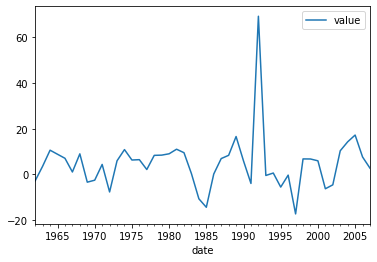

In [15]:
serie_detrend = df.diff().dropna()
serie_detrend.plot()

Volvemos a lanzar los test ADF y KPSS a la serie sin tendencia.

In [16]:
# ADF test
adf_test(serie_detrend)

ADF Statistic: -6.465207693625788
p-value: 1.4108475574140927e-08
Critial Values:
   1%, -3.584828853223594
Critial Values:
   5%, -2.9282991495198907
Critial Values:
   10%, -2.6023438271604937


Ahora, el p-valor si es menor que 0.05, y la estadística ADF es mayor que los valores críticos en valor absoluto.

In [17]:
# KPSS test
kpss_test(serie_detrend)

KPSS Statistic: 0.05036524844823132
p-value: 0.1
num lags: 0
Critial Values:
   10% : 0.347
   5% : 0.463
   2.5% : 0.574
   1% : 0.739
Result: The series is stationary


c:\Users\icalvo\Anaconda3\envs\ds3\Lib\site-packages\statsmodels\tsa\stattools.py:2022: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  warnings.warn(


Teniendo en cuenta que se obtiene el mismo resultado de los dos test, la serie es estacionaria de primer orden.